In [1]:
!pip -q install kagglehub

In [2]:
from pathlib import Path
import kagglehub
from collections import Counter

dataset_handle = "muhammadalbrham/rgb-arabic-alphabets-sign-language-dataset"

data_path = Path(kagglehub.dataset_download(
    dataset_handle,
    output_dir="/content/aasl_rgb"
))

print("مكان الداتا:", data_path)
print("محتويات المجلد:")
for p in sorted(data_path.iterdir()):
    print(p.name, "— مجلد" if p.is_dir() else "— ملف")

# نحصي الصور ونعرض أسماء مجلدات الصور، لمعرفة أسماء الفئات الفعلية
image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
images = [
    p for p in data_path.rglob("*")
    if p.is_file() and p.suffix.lower() in image_exts
]

counts = Counter(p.parent.name for p in images)
print("\nإجمالي الصور:", len(images))
print("المجلدات التي تحتوي صورًا مباشرة:", len(counts))
for name, count in sorted(counts.items()):
    print(name, count)

print("\nأمثلة على المسارات:")
for p in images[:12]:
    print(p.relative_to(data_path))

100%|██████████| 4.73G/4.73G [01:08<00:00, 73.8MB/s]

Extracting files...


مكان الداتا: /content/aasl_rgb
محتويات المجلد:
.complete — مجلد
RGB ArSL dataset — مجلد

إجمالي الصور: 7856
المجلدات التي تحتوي صورًا مباشرة: 31
Ain 244
Al 276
Alef 287
Beh 307
Dad 266
Dal 235
Feh 255
Ghain 230
Hah 246
Heh 253
Jeem 210
Kaf 264
Khah 250
Laa 268
Lam 260
Meem 253
Noon 237
Qaf 219
Reh 227
Sad 270
Seen 266
Sheen 278
Tah 226
Teh 311
Teh_Marbuta 257
Thal 202
Theh 305
Waw 249
Yeh 272
Zah 232
Zain 201

أمثلة على المسارات:
RGB ArSL dataset/Tah/Tah_208.jpg
RGB ArSL dataset/Tah/Tah_64.jpg
RGB ArSL dataset/Tah/Tah_212.jpg
RGB ArSL dataset/Tah/Tah_59.jpeg
RGB ArSL dataset/Tah/Tah_129.jpg
RGB ArSL dataset/Tah/Tah_26.jpg
RGB ArSL dataset/Tah/Tah_115.jpeg
RGB ArSL dataset/Tah/Tah_224.jpg
RGB ArSL dataset/Tah/Tah_94.jpg
RGB ArSL dataset/Tah/Tah_211.jpg
RGB ArSL dataset/Tah/Tah_36.jpg
RGB ArSL dataset/Tah/Tah_34.jpg


Ain: 244 صورة
  أمثلة أسماء: ['Ain_209.jpg', 'Ain_101.jpg', 'Ain_201.jpg', 'Ain_200.jpg', 'Ain_115.jpg']
Al: 276 صورة
  أمثلة أسماء: ['Al_261.jpeg', 'Al_41.jpg', 'Al_168.jpg', 'Al_228.jpg', 'Al_172.jpg']
Alef: 287 صورة
  أمثلة أسماء: ['Alef_63.jpeg', 'Alef_4.jpg', 'Alef_61.jpg', 'Alef_96.jpg', 'Alef_45.jpg']
Beh: 307 صورة
  أمثلة أسماء: ['Beh_189.jpg', 'Beh_47.jpg', 'Beh_122.jpg', 'Beh_302.jpg', 'Beh_81.jpg']
Dad: 266 صورة
  أمثلة أسماء: ['Dad_77.jpeg', 'Dad_194.jpeg', 'Dad_70.jpg', 'Dad_203.jpeg', 'Dad_224.jpg']
Dal: 235 صورة
  أمثلة أسماء: ['Dal_41.jpg', 'Dal_4.jpeg', 'Dal_215.jpg', 'Dal_92.jpg', 'Dal_157.jpg']
Feh: 255 صورة
  أمثلة أسماء: ['Feh_93.jpg', 'Feh_146.jpg', 'Feh_101.jpg', 'Feh_45.jpg', 'Feh_171.jpg']
Ghain: 230 صورة
  أمثلة أسماء: ['Ghain_225.jpg', 'Ghain_200.jpg', 'Ghain_64.jpg', 'Ghain_107.jpg', 'Ghain_97.jpg']
Hah: 246 صورة
  أمثلة أسماء: ['Hah_78.jpg', 'Hah_71.jpg', 'Hah_99.jpg', 'Hah_15.jpg', 'Hah_126.jpeg']
Heh: 253 صورة
  أمثلة أسماء: ['Heh_246.jpg', 'Heh_242.jpg',

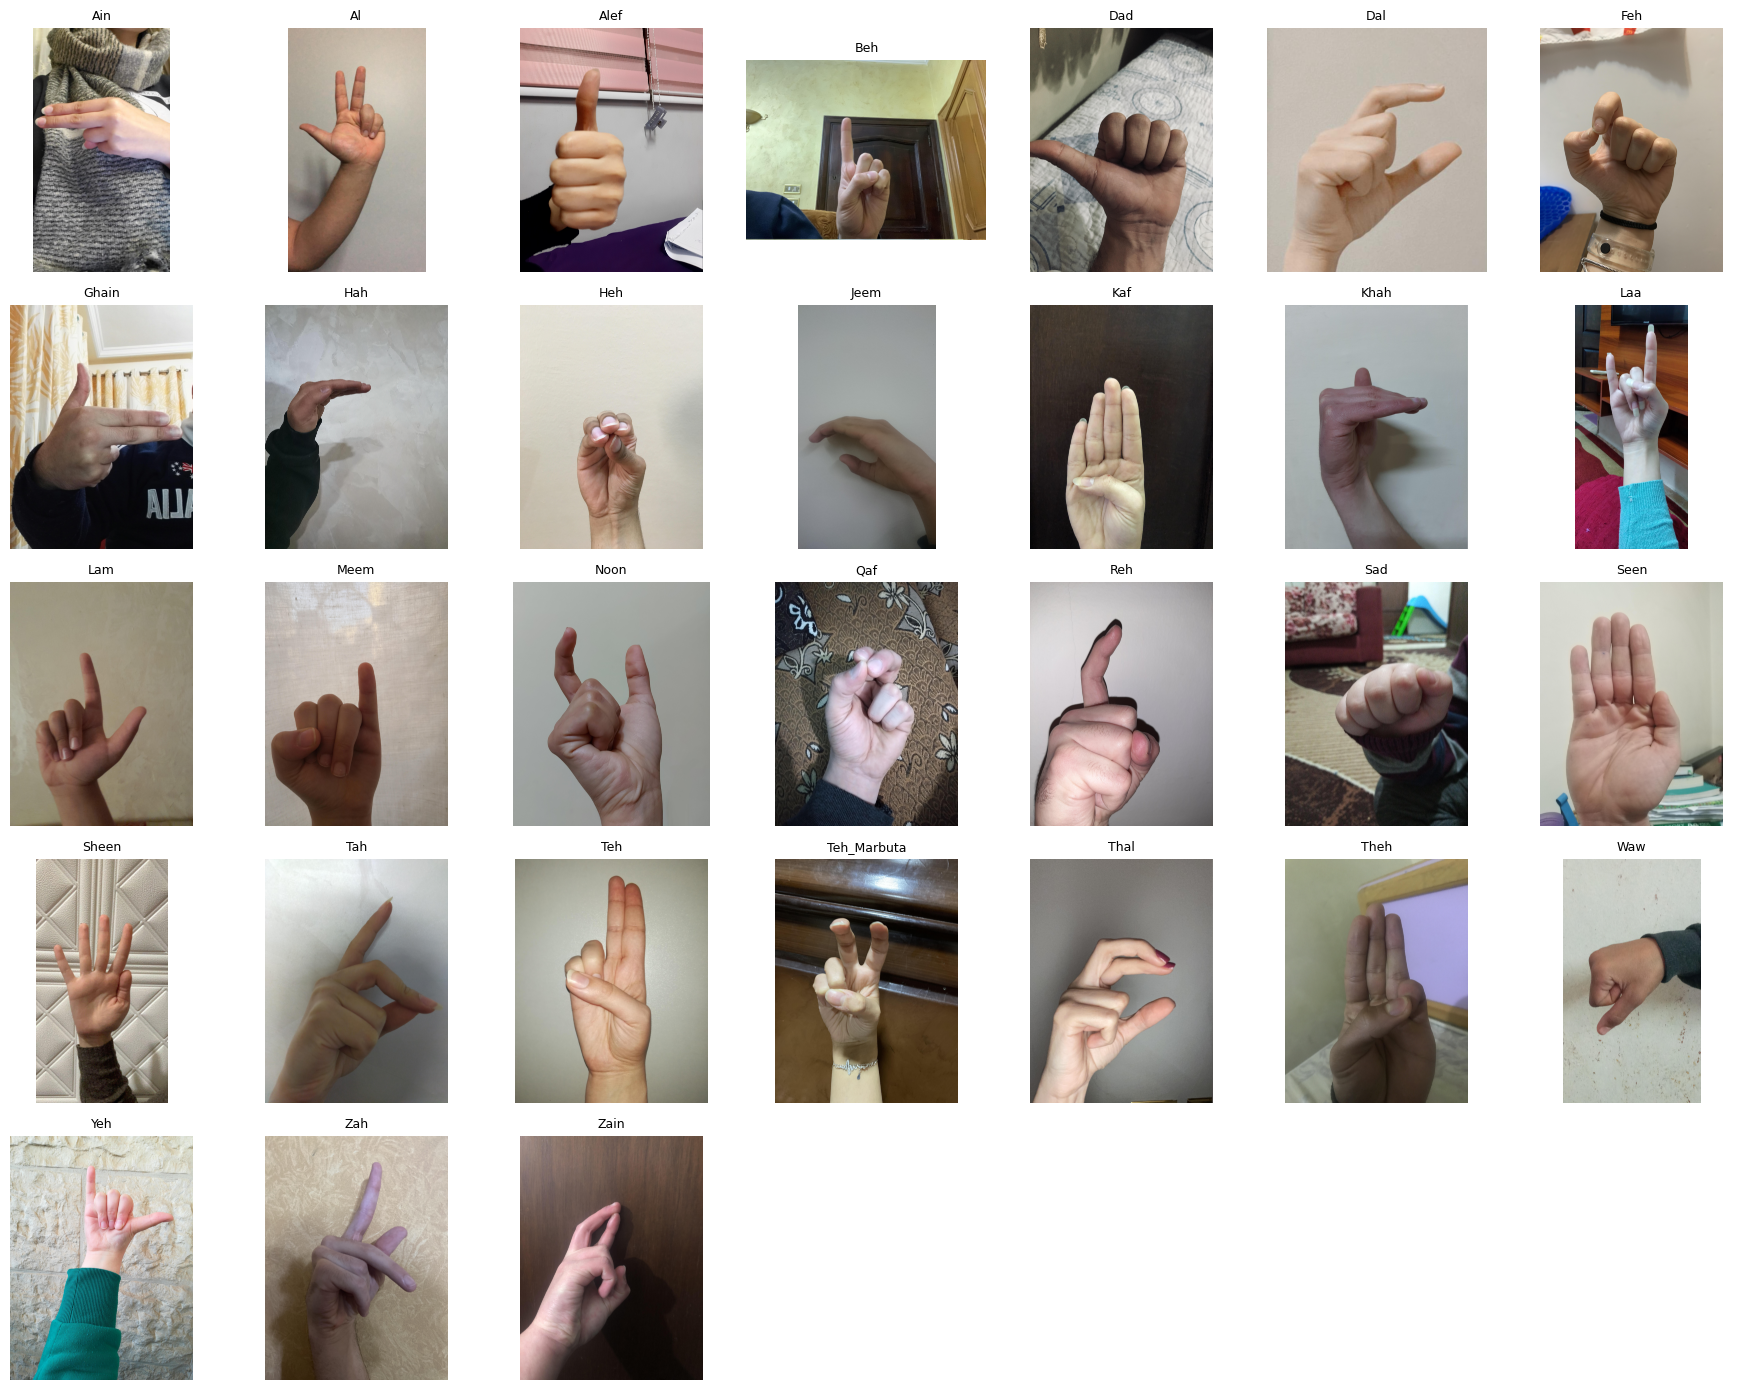

In [3]:
from pathlib import Path
from collections import defaultdict
from PIL import Image
import re
import random
import matplotlib.pyplot as plt

data_root = Path("/content/aasl_rgb/RGB ArSL dataset")
image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# أمثلة من أسماء الملفات، مع استخراج الرقم الأخير إن وُجد
number_to_classes = defaultdict(set)

for class_dir in sorted(p for p in data_root.iterdir() if p.is_dir()):
    files = [
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_exts
    ]

    print(f"{class_dir.name}: {len(files)} صورة")
    print("  أمثلة أسماء:", [p.name for p in files[:5]])

    for p in files:
        match = re.search(r"_(\d+)$", p.stem)
        if match:
            number_to_classes[match.group(1)].add(class_dir.name)

shared = [classes for classes in number_to_classes.values() if len(classes) > 1]
print("\nأرقام ملفات ظهرت في أكثر من فئة:", len(shared))
print("أمثلة:", [sorted(x) for x in shared[:10]])

# عرض صورة عشوائية من كل فئة لمراجعة شكل البيانات
class_dirs = sorted(p for p in data_root.iterdir() if p.is_dir())
fig, axes = plt.subplots(5, 7, figsize=(18, 14))

for ax, class_dir in zip(axes.flat, class_dirs):
    files = [
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_exts
    ]
    img_path = random.choice(files)
    with Image.open(img_path) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(class_dir.name, fontsize=9)
    ax.axis("off")

for ax in axes.flat[len(class_dirs):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
from pathlib import Path
from collections import Counter
import re
import pandas as pd
from sklearn.model_selection import train_test_split

data_root = Path("/content/aasl_rgb/RGB ArSL dataset")
image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

records = []

for class_dir in sorted(p for p in data_root.iterdir() if p.is_dir()):
    for image_path in class_dir.iterdir():
        if image_path.is_file() and image_path.suffix.lower() in image_exts:
            match = re.search(r"_(\d+)$", image_path.stem)
            if not match:
                raise ValueError(f"اسم الملف لا يحتوي رقمًا أخيرًا: {image_path.name}")

            records.append({
                "image_path": str(image_path),
                "label": class_dir.name,
                "group_id": match.group(1),
            })

df = pd.DataFrame(records)
groups = sorted(df["group_id"].unique())

# تقسيم المجموعات، وليس الصور المنفردة
train_groups, remaining_groups = train_test_split(
    groups, test_size=0.30, random_state=42
)
val_groups, test_groups = train_test_split(
    remaining_groups, test_size=0.50, random_state=42
)

group_to_split = {g: "train" for g in train_groups}
group_to_split.update({g: "val" for g in val_groups})
group_to_split.update({g: "test" for g in test_groups})
df["split"] = df["group_id"].map(group_to_split)

# فحص عدم وجود أي مجموعة مشتركة بين الأقسام
split_groups = {
    split: set(df.loc[df["split"] == split, "group_id"])
    for split in ("train", "val", "test")
}

print("إجمالي الصور:", len(df))
print("عدد المجموعات الرقمية:", len(groups))
print("عدد الصور حسب القسم:")
print(df["split"].value_counts())

print("\nتداخل المجموعات بين الأقسام:")
print("train/val:", len(split_groups["train"] & split_groups["val"]))
print("train/test:", len(split_groups["train"] & split_groups["test"]))
print("val/test:", len(split_groups["val"] & split_groups["test"]))

class_counts = pd.crosstab(df["label"], df["split"])
print("\nعدد الصور لكل فئة في كل قسم:")
print(class_counts)

out_dir = Path("/content/aasl_rgb_splits")
out_dir.mkdir(exist_ok=True)
df.to_csv(out_dir / "manifest.csv", index=False)
class_counts.to_csv(out_dir / "class_counts.csv")

print("\nحُفظ ملف التقسيم في:", out_dir / "manifest.csv")

إجمالي الصور: 7856
عدد المجموعات الرقمية: 311
عدد الصور حسب القسم:
split
train    5456
test     1227
val      1173
Name: count, dtype: int64

تداخل المجموعات بين الأقسام:
train/val: 0
train/test: 0
val/test: 0

عدد الصور لكل فئة في كل قسم:
split        test  train  val
label                        
Ain            37    170   37
Al             44    192   40
Alef           45    197   45
Beh            46    214   47
Dad            43    184   39
Dal            37    163   35
Feh            41    176   38
Ghain          36    160   34
Hah            38    171   37
Heh            40    176   37
Jeem           32    145   33
Kaf            42    183   39
Khah           40    173   37
Laa            43    186   39
Lam            41    181   38
Meem           40    176   37
Noon           37    165   35
Qaf            33    153   33
Reh            35    159   33
Sad            43    188   39
Seen           43    184   39
Sheen          44    192   42
Tah            35    158   33
Teh       

In [5]:
import torch
from pathlib import Path

print("GPU متاح:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("نوع GPU:", torch.cuda.get_device_name(0))

print("ملف التقسيم موجود:",
      Path("/content/aasl_rgb_splits/manifest.csv").exists())
print("مجلد الداتا موجود:",
      Path("/content/aasl_rgb/RGB ArSL dataset").exists())

GPU متاح: True
نوع GPU: Tesla T4
ملف التقسيم موجود: True
مجلد الداتا موجود: True


In [6]:
from pathlib import Path
import json
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import MobileNet_V3_Small_Weights
from PIL import Image
from sklearn.metrics import f1_score
from google.colab import drive

drive.mount("/content/drive")

# ملفات التقسيم التي أنشأناها
manifest_path = Path("/content/aasl_rgb_splits/manifest.csv")
df = pd.read_csv(manifest_path)

# تأكد أن كل الملفات موجودة
missing = [p for p in df["image_path"] if not Path(p).exists()]
if missing:
    raise FileNotFoundError(f"فيه صور ناقصة، مثال: {missing[:3]}")

classes = sorted(df["label"].unique())
class_to_idx = {name: i for i, name in enumerate(classes)}
df["target"] = df["label"].map(class_to_idx)

train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)

print("الفئات:", len(classes))
print("صور التدريب:", len(train_df), "| صور التحقق:", len(val_df))
print("الجهاز:", "GPU" if torch.cuda.is_available() else "CPU")

# حفظ ملفات التقسيم وخريطة الفئات في Drive
run_dir = Path("/content/drive/MyDrive/Signova_AASL31")
run_dir.mkdir(parents=True, exist_ok=True)
df.to_csv(run_dir / "manifest.csv", index=False)

with open(run_dir / "class_to_idx.json", "w", encoding="utf-8") as f:
    json.dump(class_to_idx, f, ensure_ascii=False, indent=2)

# تجهيز الصور بنفس القياس والتطبيع بين التدريب والتحقق
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(8),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

class ManifestImageDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row["image_path"]) as image:
            image = image.convert("RGB")
        image = self.transform(image)
        return image, int(row["target"])

train_ds = ManifestImageDataset(train_df, train_transform)
val_ds = ManifestImageDataset(val_df, eval_transform)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_loader = DataLoader(
    train_ds, batch_size=32, shuffle=True, num_workers=2,
    pin_memory=(device.type == "cuda")
)
val_loader = DataLoader(
    val_ds, batch_size=64, shuffle=False, num_workers=2,
    pin_memory=(device.type == "cuda")
)

# أوزان بسيطة لمراعاة اختلاف أعداد الصور بين الفئات
counts = train_df["target"].value_counts().reindex(range(len(classes))).values
class_weights = len(train_df) / (len(classes) * counts)
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=device)

model = models.mobilenet_v3_small(
    weights=MobileNet_V3_Small_Weights.DEFAULT
)
model.classifier[3] = nn.Linear(
    model.classifier[3].in_features, len(classes)
)
model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

epochs = 12
best_macro_f1 = -1.0
history = []

for epoch in range(epochs):
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    model.eval()
    val_loss_sum = 0.0
    val_true, val_pred = [], []

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_pred.extend(outputs.argmax(1).cpu().tolist())
            val_true.extend(labels.cpu().tolist())

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total
    val_loss = val_loss_sum / len(val_ds)
    val_acc = sum(p == y for p, y in zip(val_pred, val_true)) / len(val_true)
    val_macro_f1 = f1_score(
        val_true, val_pred, average="macro", zero_division=0
    )

    row = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_macro_f1,
    }
    history.append(row)
    pd.DataFrame(history).to_csv(run_dir / "training_history.csv", index=False)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"train loss {train_loss:.4f} | train acc {train_acc:.3f} | "
        f"val loss {val_loss:.4f} | val acc {val_acc:.3f} | "
        f"val macro-F1 {val_macro_f1:.3f}"
    )

    # الاحتفاظ بأفضل نسخة حسب Macro-F1 على val
    if val_macro_f1 > best_macro_f1:
        best_macro_f1 = val_macro_f1
        torch.save({
            "model_state_dict": model.state_dict(),
            "class_to_idx": class_to_idx,
            "epoch": epoch + 1,
            "val_accuracy": val_acc,
            "val_macro_f1": val_macro_f1,
        }, run_dir / "aasl31_best.pth")

print("\nأفضل val Macro-F1:", round(best_macro_f1, 4))
print("حُفظ أفضل نموذج ونتائج التدريب داخل MyDrive/Signova_AASL31")

Mounted at /content/drive
الفئات: 31
صور التدريب: 5456 | صور التحقق: 1173
الجهاز: GPU
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 77.4MB/s]


Epoch 1/12 | train loss 2.6809 | train acc 0.303 | val loss 1.4152 | val acc 0.637 | val macro-F1 0.630
Epoch 2/12 | train loss 0.9185 | train acc 0.755 | val loss 0.5657 | val acc 0.848 | val macro-F1 0.845
Epoch 3/12 | train loss 0.4652 | train acc 0.864 | val loss 0.3635 | val acc 0.890 | val macro-F1 0.888
Epoch 4/12 | train loss 0.2941 | train acc 0.916 | val loss 0.3071 | val acc 0.899 | val macro-F1 0.899
Epoch 5/12 | train loss 0.2226 | train acc 0.937 | val loss 0.2562 | val acc 0.920 | val macro-F1 0.919
Epoch 6/12 | train loss 0.1582 | train acc 0.954 | val loss 0.2326 | val acc 0.921 | val macro-F1 0.918
Epoch 7/12 | train loss 0.1317 | train acc 0.963 | val loss 0.2153 | val acc 0.930 | val macro-F1 0.928
Epoch 8/12 | train loss 0.1013 | train acc 0.972 | val loss 0.2108 | val acc 0.927 | val macro-F1 0.924
Epoch 9/12 | train loss 0.0842 | train acc 0.975 | val loss 0.2122 | val acc 0.922 | val macro-F1 0.920
Epoch 10/12 | train loss 0.0629 | train acc 0.985 | val loss 0.2

أفضل جولة: 11
أفضل val Macro-F1: 0.9336
Test accuracy: 0.9324
Balanced accuracy: 0.9307
Test Macro-F1: 0.93

تقرير الفئات:
              precision    recall  f1-score   support

         Ain      0.971     0.919     0.944        37
          Al      1.000     0.932     0.965        44
        Alef      1.000     1.000     1.000        45
         Beh      0.935     0.935     0.935        46
         Dad      0.977     1.000     0.989        43
         Dal      0.903     0.757     0.824        37
         Feh      0.820     1.000     0.901        41
       Ghain      0.972     0.972     0.972        36
         Hah      0.800     0.947     0.867        38
         Heh      0.944     0.850     0.895        40
        Jeem      0.909     0.938     0.923        32
         Kaf      0.930     0.952     0.941        42
        Khah      1.000     0.925     0.961        40
         Laa      0.977     0.977     0.977        43
         Lam      0.932     1.000     0.965        41
        Meem

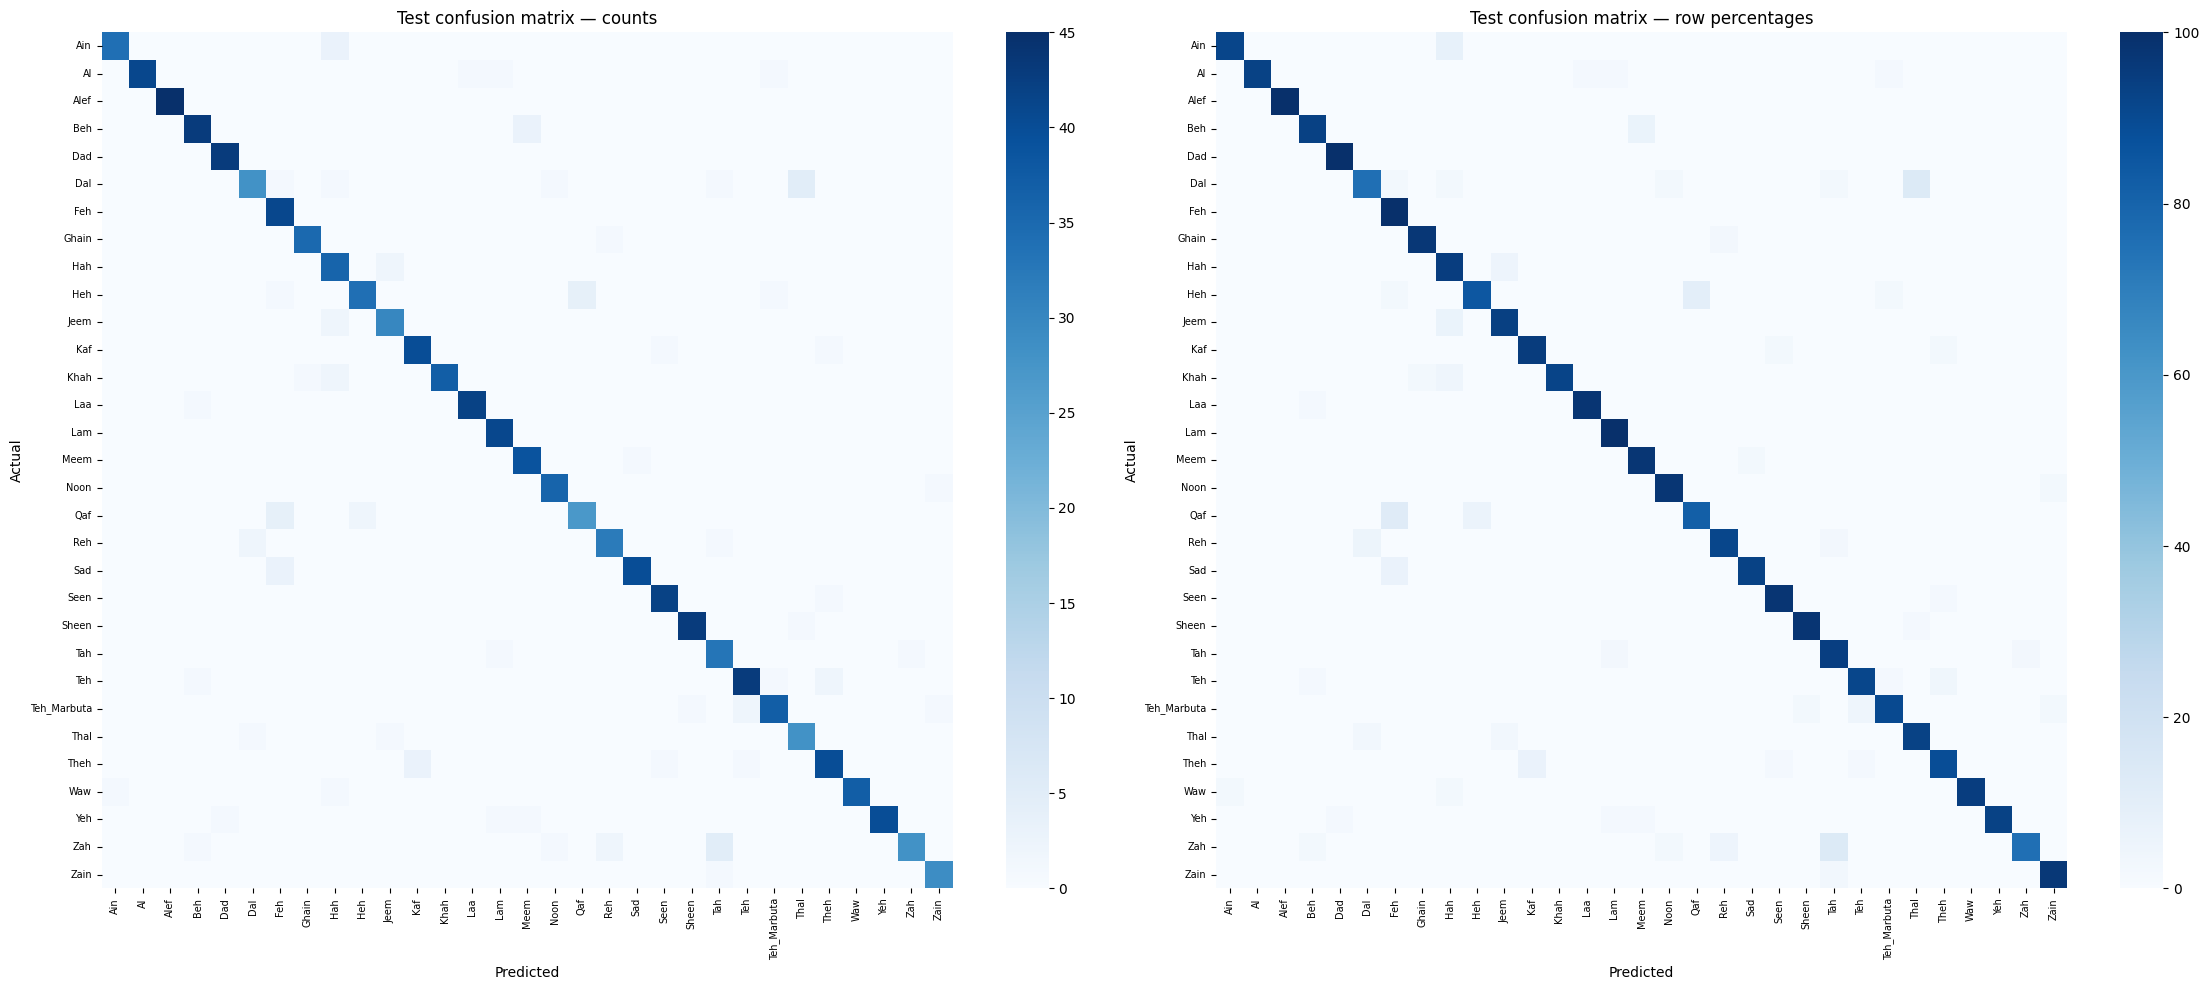

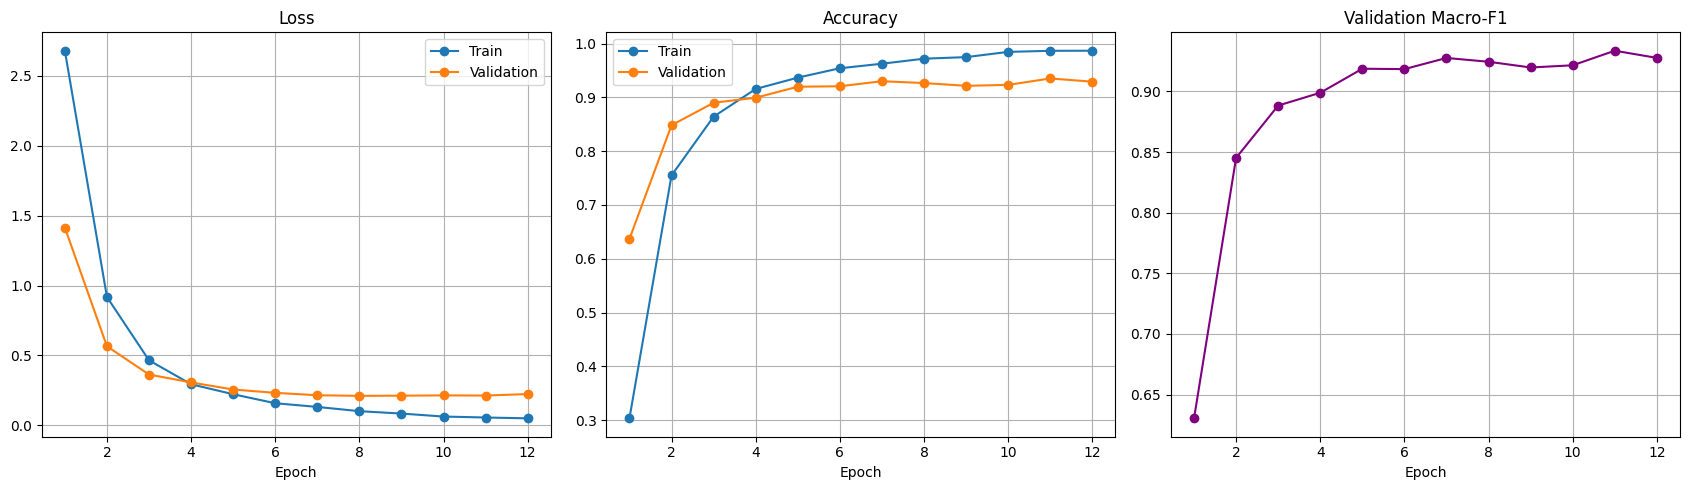


حُفظت النتائج في: /content/drive/MyDrive/Signova_AASL31


In [7]:
from pathlib import Path
import pandas as pd
import torch
import torch.nn as nn
import seaborn as sns
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix
)

run_dir = Path("/content/drive/MyDrive/Signova_AASL31")
manifest = pd.read_csv(run_dir / "manifest.csv")
checkpoint = torch.load(
    run_dir / "aasl31_best.pth",
    map_location="cpu",
    weights_only=False
)

class_to_idx = checkpoint["class_to_idx"]
classes = [name for name, idx in sorted(class_to_idx.items(), key=lambda x: x[1])]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

test_df = manifest[manifest["split"] == "test"].copy().reset_index(drop=True)
test_df["target"] = test_df["label"].map(class_to_idx)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

class ManifestDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row["image_path"]) as image:
            image = image.convert("RGB")
        return self.transform(image), int(row["target"])

test_loader = DataLoader(
    ManifestDataset(test_df, transform),
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

model = models.mobilenet_v3_small(weights=None)
model.classifier[3] = nn.Linear(model.classifier[3].in_features, len(classes))
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device).eval()

y_true, y_pred = [], []

with torch.inference_mode():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        y_pred.extend(outputs.argmax(1).cpu().tolist())
        y_true.extend(labels.tolist())

print("أفضل جولة:", checkpoint["epoch"])
print("أفضل val Macro-F1:", round(checkpoint["val_macro_f1"], 4))
print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_true, y_pred), 4))
print("Test Macro-F1:", round(f1_score(y_true, y_pred, average="macro"), 4))
print("\nتقرير الفئات:")
print(classification_report(
    y_true, y_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    digits=3,
    zero_division=0
))

# احفظ تقرير كل فئة
report = classification_report(
    y_true, y_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    output_dict=True,
    zero_division=0
)
pd.DataFrame(report).T.to_csv(run_dir / "test_classification_report.csv")

# ارسم مصفوفة الالتباس بالأعداد وبالنسب
cm = confusion_matrix(y_true, y_pred, labels=list(range(len(classes))))
cm_norm = confusion_matrix(
    y_true, y_pred,
    labels=list(range(len(classes))),
    normalize="true"
)

fig, axes = plt.subplots(1, 2, figsize=(23, 10))
sns.heatmap(cm, cmap="Blues", xticklabels=classes, yticklabels=classes, ax=axes[0])
axes[0].set_title("Test confusion matrix — counts")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    cm_norm * 100, cmap="Blues", vmin=0, vmax=100,
    xticklabels=classes, yticklabels=classes, ax=axes[1]
)
axes[1].set_title("Test confusion matrix — row percentages")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

for ax in axes:
    ax.tick_params(axis="x", rotation=90, labelsize=7)
    ax.tick_params(axis="y", rotation=0, labelsize=7)

plt.tight_layout()
fig.savefig(run_dir / "test_confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()

pd.DataFrame(cm, index=classes, columns=classes).to_csv(
    run_dir / "test_confusion_matrix_counts.csv"
)

# ارسم منحنيات التدريب والتحقق من سجل الجولات
history = pd.read_csv(run_dir / "training_history.csv")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].plot(history["epoch"], history["train_loss"], marker="o", label="Train")
axes[0].plot(history["epoch"], history["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].grid(True)
axes[0].legend()

axes[1].plot(history["epoch"], history["train_accuracy"], marker="o", label="Train")
axes[1].plot(history["epoch"], history["val_accuracy"], marker="o", label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].grid(True)
axes[1].legend()

axes[2].plot(history["epoch"], history["val_macro_f1"], marker="o", color="purple")
axes[2].set_title("Validation Macro-F1")
axes[2].set_xlabel("Epoch")
axes[2].grid(True)

plt.tight_layout()
fig.savefig(run_dir / "training_curves.png", dpi=180, bbox_inches="tight")
plt.show()

print("\nحُفظت النتائج في:", run_dir)

In [8]:
from pathlib import Path
import shutil
import zipfile
from google.colab import drive, files

drive.mount("/content/drive")

source = Path("/content/drive/MyDrive/Signova_AASL31")
package = Path("/content/Signova_AASL31_VSCode")
package.mkdir(exist_ok=True)

# الملفات اللازمة للتشغيل والتقييم
files_to_copy = [
    "aasl31_best.pth",
    "class_to_idx.json",
    "manifest.csv",
    "training_history.csv",
    "test_classification_report.csv",
    "test_confusion_matrix_counts.csv",
    "test_confusion_matrix.png",
    "training_curves.png",
]

missing = [name for name in files_to_copy if not (source / name).exists()]
if missing:
    raise FileNotFoundError(f"ملفات ناقصة في Drive: {missing}")

for name in files_to_copy:
    shutil.copy2(source / name, package / name)

# سكربت الكاميرا
webcam_code = r'''
from collections import Counter, deque
from pathlib import Path

import cv2
import torch
import torch.nn as nn
from PIL import Image
from torchvision import models, transforms

ARABIC = {
    "Ain": "ع", "Al": "ال", "Alef": "ا", "Beh": "ب",
    "Dad": "ض", "Dal": "د", "Feh": "ف", "Ghain": "غ",
    "Hah": "ح", "Heh": "ه", "Jeem": "ج", "Kaf": "ك",
    "Khah": "خ", "Laa": "لا", "Lam": "ل", "Meem": "م",
    "Noon": "ن", "Qaf": "ق", "Reh": "ر", "Sad": "ص",
    "Seen": "س", "Sheen": "ش", "Tah": "ط", "Teh": "ت",
    "Teh_Marbuta": "ة", "Thal": "ذ", "Theh": "ث",
    "Waw": "و", "Yeh": "ي", "Zah": "ظ", "Zain": "ز",
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_path = Path(__file__).resolve().parent / "aasl31_best.pth"

checkpoint = torch.load(model_path, map_location=device, weights_only=False)
class_to_idx = checkpoint["class_to_idx"]
classes = [name for name, idx in sorted(class_to_idx.items(), key=lambda x: x[1])]

model = models.mobilenet_v3_small(weights=None)
model.classifier[3] = nn.Linear(model.classifier[3].in_features, len(classes))
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device).eval()

preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

camera = cv2.VideoCapture(0, cv2.CAP_DSHOW)
if not camera.isOpened():
    camera.release()
    camera = cv2.VideoCapture(0)

if not camera.isOpened():
    raise RuntimeError(
        "لم أستطع فتح الكاميرا. أغلق Zoom أو Teams، "
        "وتأكد من السماح لـVS Code باستخدام الكاميرا."
    )

camera.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
camera.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)

recent = deque(maxlen=15)
last_printed = None

print("الكاميرا تعمل. اضغط q لإغلاقها.")
print("الجهاز:", device)

try:
    while True:
        ok, frame = camera.read()
        if not ok:
            print("تعذرت قراءة إطار من الكاميرا.")
            break

        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        tensor = preprocess(Image.fromarray(rgb)).unsqueeze(0).to(device)

        with torch.inference_mode():
            scores = torch.softmax(model(tensor)[0], dim=0)

        current_idx = int(scores.argmax().item())
        recent.append((current_idx, float(scores[current_idx].item())))

        votes = Counter(index for index, _ in recent)
        stable_idx, vote_count = votes.most_common(1)[0]
        matching_scores = [s for i, s in recent if i == stable_idx]
        average_score = sum(matching_scores) / len(matching_scores)

        stable = len(recent) == 15 and vote_count >= 11
        display = cv2.flip(frame, 1)

        if stable:
            label = classes[stable_idx]
            arabic = ARABIC.get(label, "?")
            text = f"{label} | score: {average_score:.2f}"

            if label != last_printed:
                print(f"التوقع: {label} -> {arabic} | model score: {average_score:.3f}")
                last_printed = label
            color = (0, 255, 0)
        else:
            text = "Uncertain - hold sign steady"
            color = (0, 165, 255)

        cv2.putText(
            display, text, (15, 35),
            cv2.FONT_HERSHEY_SIMPLEX, 0.75, color, 2, cv2.LINE_AA
        )
        cv2.putText(
            display, "Press q to quit", (15, 70),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2, cv2.LINE_AA
        )
        cv2.imshow("Signova AASL31", display)

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    camera.release()
    cv2.destroyAllWindows()
'''
(package / "webcam_predict.py").write_text(webcam_code, encoding="utf-8")

(package / "requirements.txt").write_text(
    "torch\n"
    "torchvision\n"
    "Pillow\n"
    "opencv-python\n",
    encoding="utf-8"
)

(package / "README.txt").write_text(
    """Signova AASL31

Contents:
- aasl31_best.pth: trained 31-class model
- webcam_predict.py: opens the local webcam and predicts a sign
- test_classification_report.csv: test metrics for every class
- test_confusion_matrix_counts.csv and test_confusion_matrix.png
- training_curves.png and training_history.csv
- manifest.csv: split assignments and image paths from the Colab run
- class_to_idx.json: exact model label order

Run on Windows from this folder:
1. Open this folder in VS Code.
2. Open Terminal (Ctrl+`).
3. Run:
   py -m venv .venv
   .venv\\Scripts\\python.exe -m pip install -r requirements.txt
   .venv\\Scripts\\python.exe webcam_predict.py
4. Press q to close the camera window.

The camera script requires a stable prediction across recent frames.
The displayed softmax score is not calibrated confidence, and the model
does not yet have a validated unknown-sign rejection mechanism.

Dataset source and license:
RGB Arabic Alphabets Sign Language Dataset on Kaggle.
License shown on Kaggle: CC BY-SA 4.0.
Keep attribution and license information when sharing derived work.
""",
    encoding="utf-8"
)

zip_path = Path("/content/Signova_AASL31_VSCode.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in package.iterdir():
        if file.is_file():
            z.write(file, arcname=file.name)

print("الحزمة جاهزة:", zip_path)
files.download(str(zip_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
الحزمة جاهزة: /content/Signova_AASL31_VSCode.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import pandas as pd
import torch
import torch.nn as nn
import numpy as np
import json

run_dir = Path("/content/drive/MyDrive/Signova_AASL31")
manifest = pd.read_csv(run_dir / "manifest.csv")
checkpoint = torch.load(
    run_dir / "aasl31_best.pth",
    map_location="cpu",
    weights_only=False
)

class_to_idx = checkpoint["class_to_idx"]
val_df = manifest[manifest["split"] == "val"].copy().reset_index(drop=True)
val_df["target"] = val_df["label"].map(class_to_idx)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

class ValDataset(Dataset):
    def __len__(self):
        return len(val_df)

    def __getitem__(self, i):
        row = val_df.iloc[i]
        with Image.open(row["image_path"]) as image:
            image = image.convert("RGB")
        return transform(image), int(row["target"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
classes = [name for name, idx in sorted(class_to_idx.items(), key=lambda x: x[1])]

model = models.mobilenet_v3_small(weights=None)
model.classifier[3] = nn.Linear(model.classifier[3].in_features, len(classes))
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device).eval()

loader = DataLoader(
    ValDataset(), batch_size=64, shuffle=False, num_workers=2
)

all_probs, all_targets = [], []
with torch.inference_mode():
    for images, labels in loader:
        logits = model(images.to(device))
        all_probs.append(torch.softmax(logits, dim=1).cpu())
        all_targets.extend(labels.tolist())

probs = torch.cat(all_probs).numpy()
targets = np.array(all_targets)

top2 = np.sort(probs, axis=1)[:, -2:]
top_score = top2[:, 1]
margin = top2[:, 1] - top2[:, 0]
predicted = probs.argmax(axis=1)

target_precision = 0.98
minimum_accepted = 50
best = None

for score_cutoff in np.arange(0.50, 0.991, 0.01):
    for margin_cutoff in np.arange(0.00, 0.501, 0.01):
        accepted = (top_score >= score_cutoff) & (margin >= margin_cutoff)
        count = int(accepted.sum())

        if count < minimum_accepted:
            continue

        precision = float((predicted[accepted] == targets[accepted]).mean())

        if precision >= target_precision:
            candidate = (count, precision, score_cutoff, margin_cutoff)
            if best is None or candidate[0] > best[0]:
                best = candidate

policy_path = run_dir / "decision_policy.json"

if best is None:
    policy = {
        "enabled": False,
        "reason": "No thresholds met target precision on validation",
        "target_validation_precision": target_precision,
    }
    print("لم نجد عتبة تحقق الهدف؛ الأفضل حاليًا أن يرد النموذج «غير متأكد».")
else:
    count, precision, score_cutoff, margin_cutoff = best
    policy = {
        "enabled": True,
        "min_score": float(score_cutoff),
        "min_margin": float(margin_cutoff),
        "target_validation_precision": target_precision,
        "observed_validation_precision": precision,
        "accepted_validation_images": count,
        "validation_coverage": float(count / len(targets)),
    }
    print("عتبة الدرجة:", round(score_cutoff, 2))
    print("عتبة الفارق:", round(margin_cutoff, 2))
    print("دقة الصور المقبولة على val:", round(precision, 4))
    print("عدد الصور المقبولة:", count, "من", len(targets))
    print("نسبة الصور التي سيقبلها:", round(count / len(targets), 3))

with open(policy_path, "w", encoding="utf-8") as f:
    json.dump(policy, f, ensure_ascii=False, indent=2)

print("حُفظت السياسة في:", policy_path)

عتبة الدرجة: 0.89
عتبة الفارق: 0.0
دقة الصور المقبولة على val: 0.9802
عدد الصور المقبولة: 1009 من 1173
نسبة الصور التي سيقبلها: 0.86
حُفظت السياسة في: /content/drive/MyDrive/Signova_AASL31/decision_policy.json


In [10]:
!pip -q install mediapipe
!wget -q -O /content/hand_landmarker.task \
  https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task

Ain: اكتشف 9/10
Al: اكتشف 9/10
Alef: اكتشف 6/10
Beh: اكتشف 9/10
Dad: اكتشف 10/10
Dal: اكتشف 8/10
Feh: اكتشف 8/10
Ghain: اكتشف 9/10
Hah: اكتشف 7/10
Heh: اكتشف 9/10
Jeem: اكتشف 8/10
Kaf: اكتشف 10/10
Khah: اكتشف 7/10
Laa: اكتشف 10/10
Lam: اكتشف 10/10
Meem: اكتشف 10/10
Noon: اكتشف 9/10
Qaf: اكتشف 6/10
Reh: اكتشف 9/10
Sad: اكتشف 9/10
Seen: اكتشف 10/10
Sheen: اكتشف 10/10
Tah: اكتشف 9/10
Teh: اكتشف 9/10
Teh_Marbuta: اكتشف 9/10
Thal: اكتشف 9/10
Theh: اكتشف 10/10
Waw: اكتشف 7/10
Yeh: اكتشف 9/10
Zah: اكتشف 8/10
Zain: اكتشف 9/10


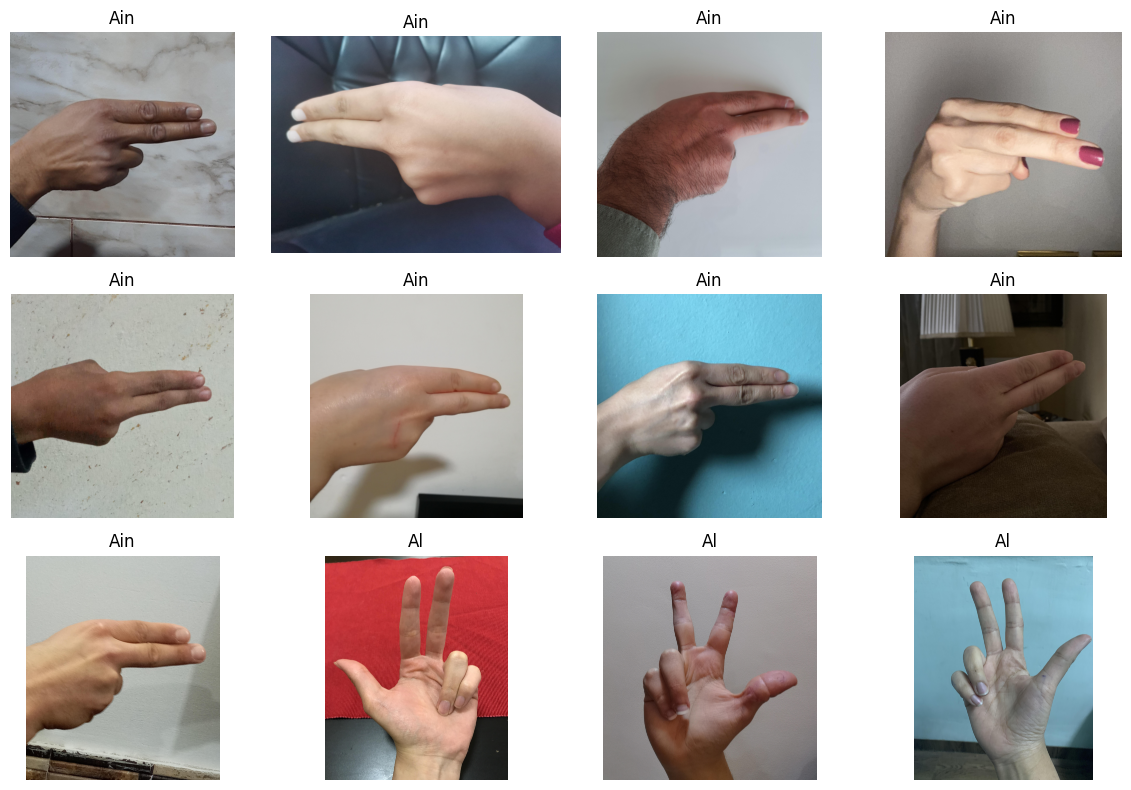

In [11]:
from pathlib import Path
from collections import Counter
from PIL import Image
import mediapipe as mp
import numpy as np
import random
import matplotlib.pyplot as plt

data_root = Path("/content/aasl_rgb/RGB ArSL dataset")
image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

BaseOptions = mp.tasks.BaseOptions
HandLandmarker = mp.tasks.vision.HandLandmarker
Options = mp.tasks.vision.HandLandmarkerOptions
RunningMode = mp.tasks.vision.RunningMode

options = Options(
    base_options=BaseOptions(model_asset_path="/content/hand_landmarker.task"),
    running_mode=RunningMode.IMAGE,
    num_hands=2,
    min_hand_detection_confidence=0.5,
)

def crop_largest_hand(rgb, landmarks_list):
    h, w = rgb.shape[:2]
    boxes = []

    for landmarks in landmarks_list:
        xs = [point.x * w for point in landmarks]
        ys = [point.y * h for point in landmarks]

        x1, x2 = min(xs), max(xs)
        y1, y2 = min(ys), max(ys)

        # مربع حول اليد مع مساحة إضافية حول الأصابع والمعصم
        side = max(x2 - x1, y2 - y1) * 1.35
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2

        left = max(0, int(cx - side / 2))
        right = min(w, int(cx + side / 2))
        top = max(0, int(cy - side / 2))
        bottom = min(h, int(cy + side / 2))

        if right > left and bottom > top:
            boxes.append((left, top, right, bottom))

    if not boxes:
        return None, None

    # لو اكتشف اليدين، نختار الصندوق الأكبر
    box = max(boxes, key=lambda b: (b[2] - b[0]) * (b[3] - b[1]))
    left, top, right, bottom = box
    return rgb[top:bottom, left:right], box

success = Counter()
total = Counter()
previews = []

with HandLandmarker.create_from_options(options) as detector:
    for class_dir in sorted(p for p in data_root.iterdir() if p.is_dir()):
        files = [
            p for p in class_dir.iterdir()
            if p.is_file() and p.suffix.lower() in image_exts
        ]
        sample = random.sample(files, min(10, len(files)))

        for image_path in sample:
            with Image.open(image_path) as image:
                rgb = np.array(image.convert("RGB"))

            result = detector.detect(
                mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
            )
            total[class_dir.name] += 1

            if result.hand_landmarks:
                crop, box = crop_largest_hand(rgb, result.hand_landmarks)
                if crop is not None:
                    success[class_dir.name] += 1
                    if len(previews) < 12:
                        previews.append((class_dir.name, crop))

for name in sorted(total):
    found = success[name]
    tried = total[name]
    print(f"{name}: اكتشف {found}/{tried}")

fig, axes = plt.subplots(3, 4, figsize=(12, 8))
for ax, (label, crop) in zip(axes.flat, previews):
    ax.imshow(crop)
    ax.set_title(label)
    ax.axis("off")

for ax in axes.flat[len(previews):]:
    ax.axis("off")

plt.tight_layout()
plt.show()